# 01 - Cleaning and modeling table

Goal: turn the 14 raw F1 CSV files into **one clean table with one row per driver per race**, ready for modeling.

Each row answers: *will this driver finish on the podium in this race?* Every feature must be known **after qualifying and before the race starts**.

All decisions are listed in `docs/cleaning-and-modeling-table.md`.

## 1. Load

The raw files are never changed. We clean the copies in memory. `DATA_DIR` is the only path to change on Kaggle.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '../data/raw'        # on Kaggle: '/kaggle/input/<dataset-name>'
OUT_DIR = '../data/processed'   # on Kaggle: '/kaggle/working'

In [2]:
names = ['circuits', 'constructors', 'constructor_results', 'constructor_standings', 'drivers', 'driver_standings',
         'lap_times', 'pit_stops', 'qualifying', 'races', 'results', 'seasons', 'sprint_results', 'status']
tables = {name: pd.read_csv(DATA_DIR + '/' + name + '.csv') for name in names}

pd.Series({name: len(df) for name, df in tables.items()})

circuits                     77
constructors                212
constructor_results       12625
constructor_standings     13391
drivers                     861
driver_standings          34863
lap_times                589081
pit_stops                 11371
qualifying                10494
races                      1125
results                   26759
seasons                      75
sprint_results              360
status                      139
dtype: int64

## 2. Audit: sentinel check and key checks

### 2.1 Column names and text

In our copy, two tables have spaces around their column names and text values (`' raceId'` instead of `raceId`), so a merge would fail.

In [3]:
print(tables['constructor_standings'].columns.tolist())
print(tables['constructor_standings'].iloc[0].tolist())

['constructorStandingsId', ' raceId', ' constructorId', ' points', ' position', ' positionText', ' wins']
[np.int64(1), np.int64(18), np.int64(1), np.float64(14.0), np.int64(1), ' "1"         ', np.int64(1)]


We strip the spaces (and quotes). Where there are none, nothing changes.

In [4]:
for df in tables.values():
    df.columns = df.columns.str.strip()

tables['constructor_results']['status'] = tables['constructor_results']['status'].str.strip().str.strip('"')
tables['constructor_standings']['positionText'] = tables['constructor_standings']['positionText'].str.strip().str.strip('"')

print(tables['constructor_standings'].columns.tolist())
print(tables['constructor_standings'].iloc[0].tolist())

['constructorStandingsId', 'raceId', 'constructorId', 'points', 'position', 'positionText', 'wins']
[np.int64(1), np.int64(18), np.int64(1), np.float64(14.0), np.int64(1), '1', np.int64(1)]


Short names for the tables we use.

In [5]:
results = tables['results']
races = tables['races']
qualifying = tables['qualifying']
drivers = tables['drivers']
circuits = tables['circuits']
status = tables['status']
driver_standings = tables['driver_standings']
constructor_standings = tables['constructor_standings']

### 2.2 Sentinel check

A sentinel is a placeholder written where a value is missing. Here it is the text `\N`. Pandas does not see it as missing, so we count it in every column of every table.

In [6]:
rows = []
for name, df in tables.items():
    counts = (df == '\\N').sum()
    for col in counts[counts > 0].index:
        rows.append([name + '.' + col, counts[col], round(counts[col] / len(df), 3)])

sentinels = pd.DataFrame(rows, columns=['column', 'n_sentinel', 'share'])
sentinels

,column,n_sentinel,share
0,constructor_results.status,12608,0.999
1,drivers.number,802,0.931
2,drivers.code,757,0.879
3,qualifying.q1,156,0.015
4,qualifying.q2,4625,0.441
5,qualifying.q3,6819,0.650
6,races.time,731,0.650
7,races.fp1_date,1035,0.920
8,races.fp1_time,1057,0.940
9,races.fp2_date,1035,0.920


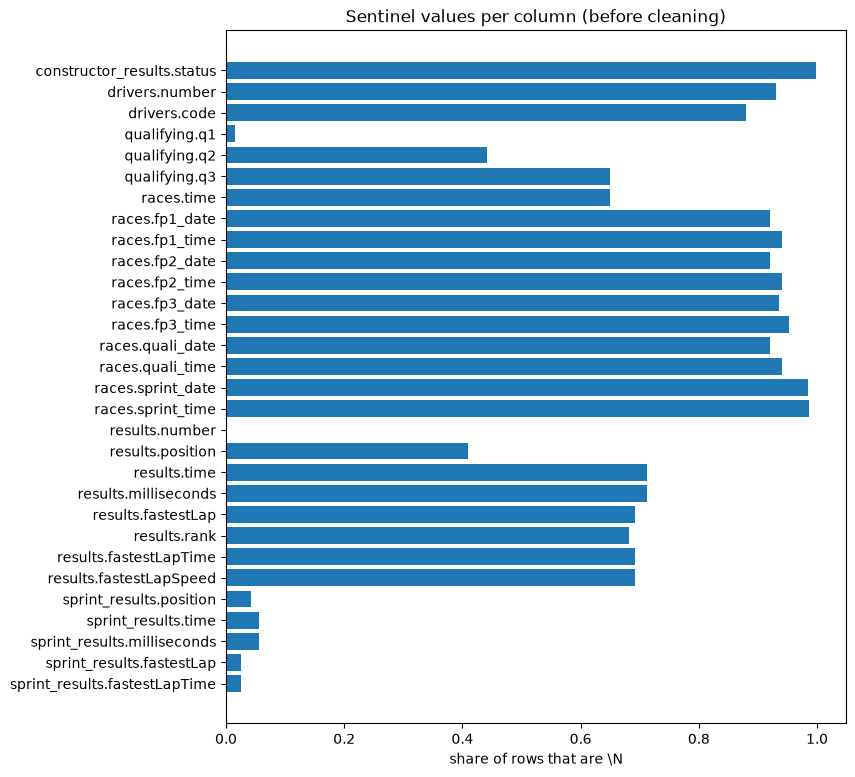

In [7]:
plt.figure(figsize=(8, 9))
plt.barh(sentinels['column'], sentinels['share'])
plt.xlabel('share of rows that are \\N')
plt.title('Sentinel values per column (before cleaning)')
plt.gca().invert_yaxis()
plt.show()

Six tables have sentinels. They make sense: `results.position` is `\N` when the driver was not classified, and `q2`/`q3` are `\N` for drivers knocked out earlier.

There is a second kind of missing value: cells that are just empty. Pandas already reads those as `NaN`.

In [8]:
qualifying.isna().sum()

qualifyId         0
raceId            0
driverId          0
constructorId     0
number            0
position          0
q1                0
q2               22
q3               46
dtype: int64

### 2.3 Primary keys

A primary key identifies one row. It must have no repeated and no empty value.

In [9]:
primary_keys = {
    'circuits': ['circuitId'], 'constructors': ['constructorId'], 'constructor_results': ['constructorResultsId'],
    'constructor_standings': ['constructorStandingsId'], 'drivers': ['driverId'],
    'driver_standings': ['driverStandingsId'], 'lap_times': ['raceId', 'driverId', 'lap'],
    'pit_stops': ['raceId', 'driverId', 'stop'], 'qualifying': ['qualifyId'], 'races': ['raceId'],
    'results': ['resultId'], 'seasons': ['year'], 'sprint_results': ['resultId'], 'status': ['statusId'],
}

rows = []
for name, key in primary_keys.items():
    rows.append([name, key, tables[name].duplicated(key).sum(), tables[name][key].isna().sum().sum()])

pd.DataFrame(rows, columns=['table', 'primary_key', 'duplicates', 'nulls'])

,table,primary_key,duplicates,nulls
0,circuits,[circuitId],0,0
1,constructors,[constructorId],0,0
2,constructor_results,[constructorResultsId],0,0
3,constructor_standings,[constructorStandingsId],0,0
4,drivers,[driverId],0,0
5,driver_standings,[driverStandingsId],0,0
6,lap_times,"[raceId, driverId, lap]",0,0
7,pit_stops,"[raceId, driverId, stop]",0,0
8,qualifying,[qualifyId],0,0
9,races,[raceId],0,0


### 2.4 Foreign keys

A foreign key points at another table. We count the values that do not exist in the parent table (orphans).

In [10]:
foreign_keys = [
    ('races', 'circuitId', 'circuits'), ('races', 'year', 'seasons'),
    ('results', 'raceId', 'races'), ('results', 'driverId', 'drivers'),
    ('results', 'constructorId', 'constructors'), ('results', 'statusId', 'status'),
    ('qualifying', 'raceId', 'races'), ('qualifying', 'driverId', 'drivers'),
    ('qualifying', 'constructorId', 'constructors'),
    ('sprint_results', 'raceId', 'races'), ('sprint_results', 'driverId', 'drivers'),
    ('sprint_results', 'constructorId', 'constructors'), ('sprint_results', 'statusId', 'status'),
    ('driver_standings', 'raceId', 'races'), ('driver_standings', 'driverId', 'drivers'),
    ('constructor_standings', 'raceId', 'races'), ('constructor_standings', 'constructorId', 'constructors'),
    ('constructor_results', 'raceId', 'races'), ('constructor_results', 'constructorId', 'constructors'),
    ('lap_times', 'raceId', 'races'), ('lap_times', 'driverId', 'drivers'),
    ('pit_stops', 'raceId', 'races'), ('pit_stops', 'driverId', 'drivers'),
]

rows = []
for child, col, parent in foreign_keys:
    rows.append([child, col, parent, (~tables[child][col].isin(tables[parent][col])).sum()])

pd.DataFrame(rows, columns=['table', 'column', 'points_to', 'orphans'])

,table,column,points_to,orphans
0,races,circuitId,circuits,0
1,races,year,seasons,0
2,results,raceId,races,0
3,results,driverId,drivers,0
4,results,constructorId,constructors,0
5,results,statusId,status,0
6,qualifying,raceId,races,0
7,qualifying,driverId,drivers,0
8,qualifying,constructorId,constructors,0
9,sprint_results,raceId,races,0


All 14 primary keys are unique and complete, and all 23 links have no orphans.

### 2.5 The modeling key

Our table needs one row per (`raceId`, `driverId`). Is that pair unique in `results`?

In [11]:
results.duplicated(['raceId', 'driverId']).sum()

np.int64(91)

No. Some drivers appear more than once in a race. We fix this in section 4.

## 3. EDA before cleaning

We add the year and race name to a copy of `results`, and keep two series to compare after cleaning.

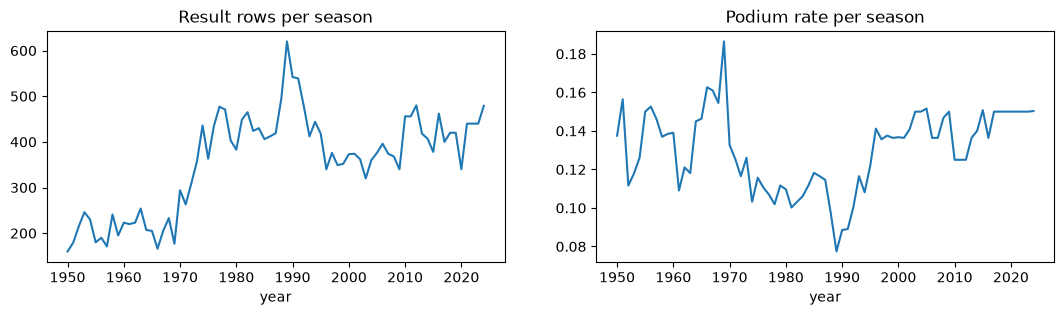

In [12]:
eda = results.merge(races[['raceId', 'year', 'name']], on='raceId')
eda['podium'] = eda['positionOrder'] <= 3

rows_before = eda.groupby('year').size()
podium_before = eda.groupby('year')['podium'].mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 3))
rows_before.plot(ax=ax[0], title='Result rows per season')
podium_before.plot(ax=ax[1], title='Podium rate per season')
plt.show()

Rows per season are not steady: the late 1980s and early 1990s have many more entries. The podium rate drops in those years, because every race has about three podiums whatever the number of rows.

`positionText` says why a driver has no position.

In [13]:
eda['positionText'][~eda['positionText'].str.isdigit()].value_counts()

positionText
R    8897
F    1368
W     336
N     190
D     151
E       9
Name: count, dtype: int64

`R` = retired, `F` = failed to qualify, `W` = withdrew, `N` = not classified, `D` = disqualified, `E` = excluded. `F` and `W` drivers never started, which explains the extra rows.

rows with grid 0: 1638


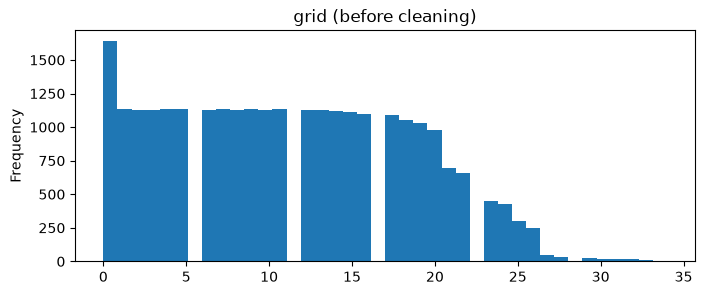

In [14]:
print('rows with grid 0:', (eda['grid'] == 0).sum())

eda['grid'].plot(kind='hist', bins=40, figsize=(8, 3), title='grid (before cleaning)')
plt.show()

`grid` has a spike at 0, which is not a real starting position. Next, how many races have qualifying data?

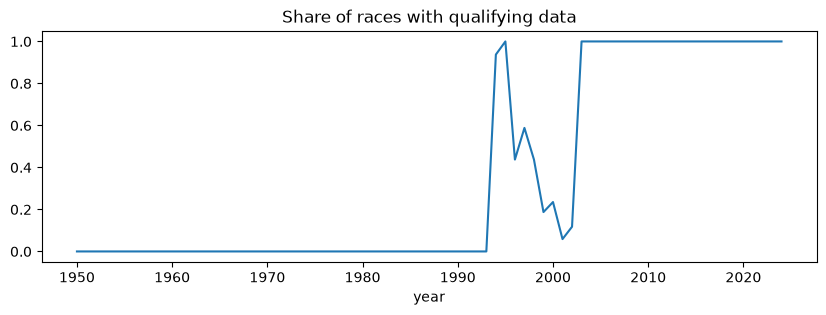

In [15]:
races['raceId'].isin(qualifying['raceId']).groupby(races['year']).mean().plot(figsize=(10, 3), title='Share of races with qualifying data')
plt.show()

Qualifying data starts in 1994, is patchy from 1996 to 2002, and is complete from 2003. This is the *qualifying-coverage drift* MS1 warns about.

Last, the Indianapolis 500, which was part of the championship from 1950 to 1960.

In [16]:
indy = eda[eda['name'] == 'Indianapolis 500']
others = eda[(eda['name'] != 'Indianapolis 500') & (eda['year'] <= 1960)]

print('rows:', len(indy), '| races:', indy['raceId'].nunique(), '| drivers:', indy['driverId'].nunique())
print('drivers who also raced elsewhere:', indy[indy['driverId'].isin(others['driverId'])]['driverId'].nunique())

rows: 405 | races: 11 | drivers: 107
drivers who also raced elsewhere: 3


Almost none of the Indianapolis drivers raced anywhere else. It is nearly a separate set of drivers.

## 4. Cleaning

### 4.1 Sentinel

Replace `\N` with a real missing value in every table, then count again.

In [17]:
for df in tables.values():
    df.replace('\\N', np.nan, inplace=True)

sum((df == '\\N').sum().sum() for df in tables.values())

np.int64(0)

### 4.2 Types

The columns that had `\N` are still text, and dates are text too.

In [18]:
num_cols = ['number', 'position', 'milliseconds', 'fastestLap', 'rank', 'fastestLapSpeed']
print(results[num_cols].dtypes.tolist(), races['date'].dtype, drivers['dob'].dtype)

[<StringDtype(na_value=nan)>, <StringDtype(na_value=nan)>, <StringDtype(na_value=nan)>, <StringDtype(na_value=nan)>, <StringDtype(na_value=nan)>, <StringDtype(na_value=nan)>] str str


In [19]:
results[num_cols] = results[num_cols].apply(pd.to_numeric)
races['date'] = pd.to_datetime(races['date'])
drivers['dob'] = pd.to_datetime(drivers['dob'])

print(results[num_cols].dtypes.tolist(), races['date'].dtype, drivers['dob'].dtype)

[dtype('float64'), dtype('float64'), dtype('float64'), dtype('float64'), dtype('float64'), dtype('float64')] datetime64[us] datetime64[us]


### 4.3 Lap times to seconds

Qualifying lap times are text like `1:26.572`. Adding `00:` in front makes it hours:minutes:seconds, which pandas can read as a duration.

In [20]:
for col in ['q1', 'q2', 'q3']:
    qualifying[col + '_sec'] = pd.to_timedelta('00:' + qualifying[col]).dt.total_seconds()

qualifying[['q1', 'q1_sec', 'q2', 'q2_sec', 'q3', 'q3_sec']].describe().loc[['count', 'min', 'max']]

,q1_sec,q2_sec,q3_sec
count,10338.000,5847.000,3629.000
min,53.904,53.647,53.377
max,1002.640,132.470,129.776


The largest `q1_sec` is about 1000 seconds, more than 16 minutes. We look at the slowest laps.

In [21]:
qualifying.nlargest(4, 'q1_sec')[['raceId', 'driverId', 'position', 'q1', 'q1_sec']]

,raceId,driverId,position,q1,q1_sec
2567,255,87,24,16:42.640,1002.640
2853,267,113,26,2:33.885,153.885
2852,267,111,25,2:31.755,151.755
2851,267,104,24,2:30.931,150.931


One value is far from all the others. It is a data error, so we set it to missing. The other slow laps are possible (a wet session), so they stay.

In [22]:
qualifying.loc[qualifying['q1_sec'] > 600, 'q1_sec'] = np.nan

### 4.4 Stray spaces

One nationality has a space around it.

In [23]:
print((drivers['nationality'] != drivers['nationality'].str.strip()).sum())

drivers['nationality'] = drivers['nationality'].str.strip()

1


### 4.5 Duplicates: one driver, several rows in a race

rows involved: 176 | driver-race pairs: 85 | rows to drop: 91


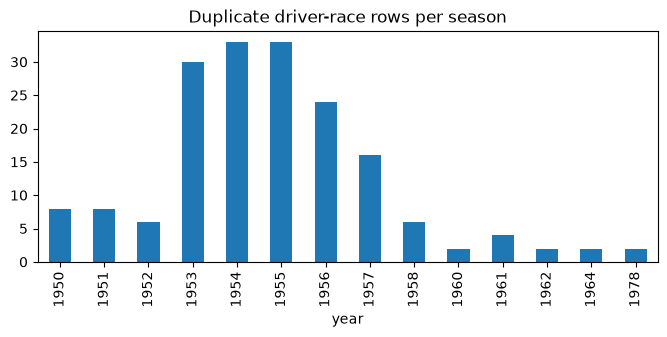

In [24]:
key = ['raceId', 'driverId']
dups = results[results.duplicated(key, keep=False)].merge(races[['raceId', 'year', 'name']], on='raceId')

print('rows involved:', len(dups), '| driver-race pairs:', len(dups.drop_duplicates(key)), '| rows to drop:', results.duplicated(key).sum())

dups.groupby('year').size().plot(kind='bar', figsize=(8, 3), title='Duplicate driver-race rows per season')
plt.show()

Almost all are from the 1950s and early 1960s. These are **shared drives**: a driver could take over a teammate's car during the race, so he has one row per car.

**Rule: keep the row with the best (lowest) `positionOrder`.** The row answers "did this driver finish on the podium?", and a podium in a shared car is an official podium for that driver.

Limitation: the kept row can carry the grid of the car the driver took over, not the car he started in. The data does not say which car he started in.

In [25]:
n_raw = len(results)
results = results.sort_values('positionOrder').drop_duplicates(key)
n_dedup = len(results)

print(n_raw, '->', n_dedup, '| duplicates left:', results.duplicated(key).sum())

26759 -> 26668 | duplicates left: 0


The opposite case also exists: **two drivers sharing one car**. Both get the car's finishing position, so a few races have more than three podium rows.

In [26]:
results[results['positionOrder'] <= 3].groupby('raceId').size().value_counts().sort_index()

3    1107
4      16
5       2
Name: count, dtype: int64

We keep these rows. Each driver appears once, and both were officially on the podium.

### 4.6 Remove rows that are not real prediction cases

`df` is the cleaned results with the race information and the status text. We remove:

- the **Indianapolis 500** (a separate set of drivers on a very different track),
- drivers who **never started**: `F` (failed to qualify) and `W` (withdrew). After qualifying we already know they are out.

In [27]:
race_cols = races[['raceId', 'year', 'round', 'date', 'name', 'circuitId']].rename(columns={'name': 'race_name'})
df = results.merge(race_cols, on='raceId').merge(status, on='statusId')

df = df[df['race_name'] != 'Indianapolis 500']
n_indy = len(df)

df = df[~df['positionText'].isin(['F', 'W'])]
n_fw = len(df)

print(n_dedup, '->', n_indy, '->', n_fw)

26668 -> 26287 -> 24586


### 4.7 Grid 0

What is left with `grid` 0, and did those drivers complete any lap?

In [28]:
zero = df[df['grid'] == 0]
pd.crosstab(zero['year'] >= 2015, zero['laps'] > 0, rownames=['2015 or later'], colnames=['did laps'])

did laps,False,True
2015 or later,,
False,14,0
True,1,72


In [29]:
zero[zero['laps'] == 0]['status'].value_counts()

status
Excluded        6
Disqualified    6
Battery         1
Underweight     1
Retired         1
Name: count, dtype: int64

Two groups:

- **0 laps**: excluded or disqualified before the race, or the car failed before the start. They did not start, so we remove them too.
- **Did laps**: **pit-lane starts**. The car starts behind the whole grid. Left as 0, the model would read it as better than pole, so we replace 0 with **last grid place in that race + 1**.

In [30]:
df = df[~((df['grid'] == 0) & (df['laps'] == 0))]
n_clean = len(df)

last_place = df.groupby('raceId')['grid'].transform('max')
df['grid'] = df['grid'].where(df['grid'] > 0, last_place + 1)

print(n_fw, '->', n_clean, '| grid 0 left:', (df['grid'] == 0).sum())

24586 -> 24571 | grid 0 left: 0


## 5. EDA after cleaning

raw                26759
duplicates         26668
Indianapolis       26287
F and W            24586
grid 0, no laps    24571
dtype: int64


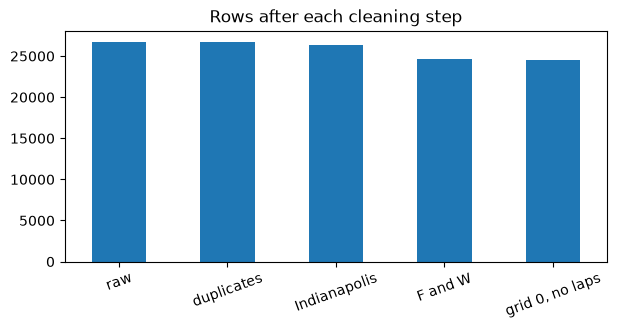

In [31]:
steps = pd.Series({'raw': n_raw, 'duplicates': n_dedup, 'Indianapolis': n_indy, 'F and W': n_fw, 'grid 0, no laps': n_clean})
print(steps)

steps.plot(kind='bar', figsize=(7, 3), title='Rows after each cleaning step')
plt.xticks(rotation=20)
plt.show()

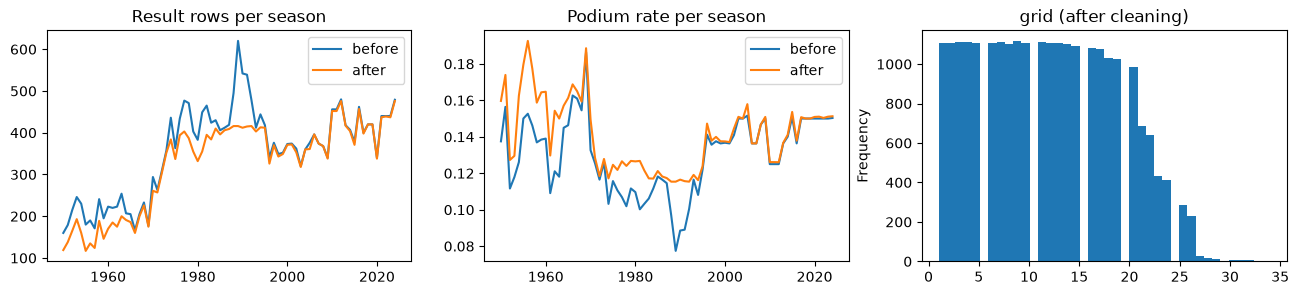

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3))
ax[0].plot(rows_before, label='before')
ax[0].plot(df.groupby('year').size(), label='after')
ax[0].set_title('Result rows per season')
ax[0].legend()
ax[1].plot(podium_before, label='before')
ax[1].plot((df['positionOrder'] <= 3).groupby(df['year']).mean(), label='after')
ax[1].set_title('Podium rate per season')
ax[1].legend()
df['grid'].plot(kind='hist', bins=40, ax=ax[2], title='grid (after cleaning)')
plt.show()

- The bump of the late 1980s and early 1990s is much smaller: most of those rows were drivers who never started.
- The seasons with the lowest podium rate move up, for the same reason.
- The spike at grid 0 is gone.

## 6. Target

`podium` is 1 when the driver finished in the top 3. `positionOrder` is filled for every row.

In [33]:
df['podium'] = (df['positionOrder'] <= 3).astype(int)

df['podium'].mean()

np.float64(0.13670587277685076)

About 1 row in 7 is a podium, so the classes are imbalanced. Before any "previous race" feature the rows must be in time order, and `raceId` is not:

In [34]:
races[races['raceId'] <= 2][['raceId', 'year', 'round', 'date']]

,raceId,year,round,date
0,1,2009,1,2009-03-29
1,2,2009,2,2009-04-05


`raceId` 1 is a 2009 race, so we sort by `date`.

In [35]:
df = df.sort_values(['date', 'positionOrder']).reset_index(drop=True)

## 7. Features

Features that use past results only look at **earlier** races.

### 7.1 Grid

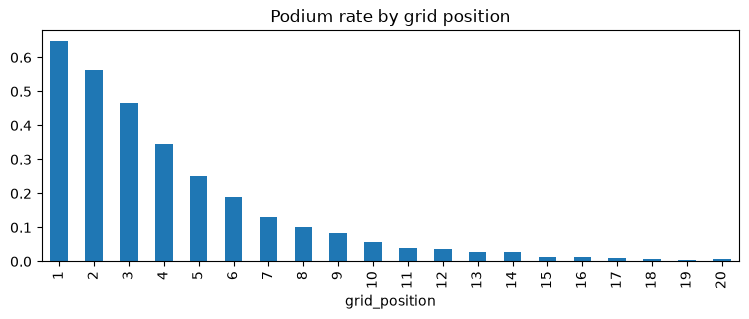

In [36]:
df = df.rename(columns={'grid': 'grid_position'})

df.groupby('grid_position')['podium'].mean().head(20).plot(kind='bar', figsize=(9, 3), title='Podium rate by grid position')
plt.show()

The podium rate falls quickly with grid position, so `grid_position` is a strong feature.

Fields had 20 cars in some years and more than 30 in others, so the same grid number does not always mean the same thing. `grid_position_relative` puts grid on a 0 to 1 scale inside each race. We keep both and compare them later.

In [37]:
df['front_row_start'] = (df['grid_position'] <= 2).astype(int)
df['grid_position_relative'] = df['grid_position'] / df.groupby('raceId')['grid_position'].transform('max')

### 7.2 Qualifying

The gap between a driver's best lap and the fastest lap (pole), as a percentage, so a short circuit and a long one can be compared.

In [38]:
qualifying['best_sec'] = qualifying[['q1_sec', 'q2_sec', 'q3_sec']].min(axis=1)
qualifying['pole_sec'] = qualifying.groupby('raceId')['best_sec'].transform('min')
qualifying['qualifying_gap_to_pole_percent'] = (qualifying['best_sec'] / qualifying['pole_sec'] - 1) * 100

quali_small = qualifying[['raceId', 'driverId', 'position', 'qualifying_gap_to_pole_percent']].rename(columns={'position': 'qualifying_position'})
df = df.merge(quali_small, on=['raceId', 'driverId'], how='left')

`has_qualifying_data` is set **per race**: 1 when the race has qualifying data, 0 when it has none, so all drivers of a race are treated the same.

Grid and qualifying position are almost the same number, so we keep only their **difference**: `grid_penalty_places` is positive when a driver starts further back than he qualified. Without a qualifying position it is 0.

In [39]:
df['has_qualifying_data'] = df['raceId'].isin(qualifying['raceId']).astype(int)
print('correlation grid position vs qualifying position:', round(df['grid_position'].corr(df['qualifying_position']), 3))

df['grid_penalty_places'] = (df['grid_position'] - df['qualifying_position']).fillna(0)

correlation grid position vs qualifying position: 0.97


Does the penalty add anything beyond grid? We compare drivers who start 7th to 10th.

In [40]:
mid = df[df['has_qualifying_data'].eq(1) & df['grid_position'].between(7, 10)]
mid.groupby(mid['grid_penalty_places'] >= 3)['podium'].agg(['mean', 'count'])

,mean,count
grid_penalty_places,,
False,0.057351,1918
True,0.217391,46


Drivers moved back 3 or more places reach the podium far more often than others starting from the same place. They are fast cars out of position, and `grid_position` alone cannot see that.

### 7.3 Driver form

Form is how a driver did **in his previous races**. The key step is `shift()`: it moves every value one race down, so a row only sees results from before it.

In [41]:
def past_mean(s, n):
    # mean of the previous n rows, not counting the current row
    return s.shift().rolling(n, min_periods=1).mean()

`Finished` and `+1 Lap`, `+2 Laps`, ... mean the driver reached the flag. Everything else is a retirement (`retired`).

In [42]:
df['retired'] = (~df['status'].str.contains('Finished|Lap')).astype(int)

by_driver = df.groupby('driverId')
df['driver_races_before'] = by_driver.cumcount()
df['driver_podium_rate_last_5_races'] = by_driver['podium'].transform(past_mean, n=5)
df['driver_average_finish_last_5_races'] = by_driver['positionOrder'].transform(past_mean, n=5)
df['driver_retirement_rate_last_10_races'] = by_driver['retired'].transform(past_mean, n=10)
df['driver_career_podium_rate'] = by_driver['podium'].transform(lambda s: s.shift().expanding().mean())
df['driver_podium_rate_at_circuit'] = df.groupby(['driverId', 'circuitId'])['podium'].transform(lambda s: s.shift().expanding().mean())

Check on one driver: the first race is empty, and each value only uses the rows above it.

In [43]:
df[df['driverId'] == 1][['date', 'race_name', 'podium', 'driver_races_before', 'driver_podium_rate_last_5_races', 'driver_career_podium_rate']].head(6)

,date,race_name,podium,driver_races_before,driver_podium_rate_last_5_races,driver_career_podium_rate
17099,2007-03-18,Australian Grand Prix,1,0,NaN,NaN
17120,2007-04-08,Malaysian Grand Prix,1,1,1.0,1.0
17142,2007-04-15,Bahrain Grand Prix,1,2,1.0,1.0
17164,2007-05-13,Spanish Grand Prix,1,3,1.0,1.0
17186,2007-05-27,Monaco Grand Prix,1,4,1.0,1.0
17207,2007-06-10,Canadian Grand Prix,1,5,1.0,1.0


### 7.4 Constructor form

We do not use the constructor's identity, only how the team performed recently. This also works for a team the model has never seen. A renamed team gets a new `constructorId`, so its history starts empty (a known limitation).

For mechanical retirements we need the statuses where a part of the car failed.

In [44]:
mechanical = [
    'Engine', 'Power Unit', 'ERS', 'Turbo', 'Battery', 'Power loss', 'Spark plugs', 'Exhaust', 'Gearbox',
    'Transmission', 'Clutch', 'Driveshaft', 'Drivetrain', 'Differential', 'Hydraulics', 'Electrical',
    'Electronics', 'Throttle', 'Brakes', 'Brake duct', 'Suspension', 'Steering', 'Wheel', 'Wheel nut',
    'Vibrations', 'Oil leak', 'Oil pressure', 'Water leak', 'Water pressure', 'Water pump', 'Radiator',
    'Overheating', 'Cooling system', 'Fuel pressure', 'Fuel leak', 'Fuel system', 'Fuel pump', 'Out of fuel',
    'Front wing', 'Rear wing', 'Undertray', 'Seat', 'Mechanical', 'Technical',
    # older statuses
    'Driver Seat', 'Broken wing', 'Heat shield fire', 'Wheel rim', 'Track rod', 'Engine fire', 'Engine misfire',
    'Pneumatics', 'Fire', 'Wheel bearing', 'Oil line', 'Launch control', 'Fuel', 'Ignition', 'Chassis',
    'Halfshaft', 'Crankshaft', 'Alternator', 'Safety belt', 'Oil pump', 'Injection', 'Distributor', 'CV joint',
    'Magneto', 'Supercharger', 'Fuel pipe', 'Oil pipe', 'Axle', 'Water pipe',
]
df['mechanical_retirement'] = df['status'].isin(mechanical).astype(int)

# the retirements we did NOT count as mechanical
df[(df['retired'] == 1) & (df['mechanical_retirement'] == 0)]['status'].value_counts().head(12)

status
Accident            981
Collision           850
Spun off            777
Not classified      172
Disqualified        140
Retired              97
Collision damage     60
Tyre                 54
Handling             53
Puncture             41
Physical             30
Withdrew             20
Name: count, dtype: int64

A team has two cars in a race. Shifting row by row would let one car see its teammate's result **from the same race**. So we first make one row per team per race, then look back.

In [45]:
con_race = df.groupby(['constructorId', 'date', 'raceId'])[['podium', 'positionOrder', 'mechanical_retirement']].mean().reset_index()

by_con = con_race.groupby('constructorId')
con_race['constructor_podium_rate_last_5_races'] = by_con['podium'].transform(past_mean, n=5)
con_race['constructor_average_finish_last_5_races'] = by_con['positionOrder'].transform(past_mean, n=5)
con_race['constructor_mechanical_retirement_rate_last_10_races'] = by_con['mechanical_retirement'].transform(past_mean, n=10)

con_cols = ['constructorId', 'raceId', 'constructor_podium_rate_last_5_races', 'constructor_average_finish_last_5_races', 'constructor_mechanical_retirement_rate_last_10_races']
df = df.merge(con_race[con_cols], on=['constructorId', 'raceId'], how='left')

Check: both cars of a team have the same value in a race, and it does not include that race.

In [46]:
df[(df['constructorId'] == 131) & (df['year'] == 2019)][['date', 'race_name', 'driverId', 'podium', 'constructor_podium_rate_last_5_races']].head(4)

,date,race_name,driverId,podium,constructor_podium_rate_last_5_races
22024,2019-03-17,Australian Grand Prix,822,1,0.5
22025,2019-03-17,Australian Grand Prix,1,1,0.5
22044,2019-03-31,Bahrain Grand Prix,1,1,0.5
22045,2019-03-31,Bahrain Grand Prix,822,1,0.5


### 7.5 Standings before the race

The standings tables give the points **after** each race, so the row of the same race would leak the result. We use the row of the **previous round** of the same season.

Points depend on the season's points system (a win was worth 8, 9, 10 or 25), so we divide by the leader's points.

In [47]:
races = races.sort_values(['year', 'round'])
races['prev_raceId'] = races.groupby('year')['raceId'].shift()
df = df.merge(races[['raceId', 'prev_raceId']], on='raceId', how='left')

driver_standings['points_share'] = driver_standings['points'] / driver_standings.groupby('raceId')['points'].transform('max')
drv_prev = driver_standings[['raceId', 'driverId', 'points_share', 'position', 'wins']]
drv_prev.columns = ['prev_raceId', 'driverId', 'driver_points_share_before_race', 'driver_standing_position_before_race', 'driver_season_wins_before_race']
df = df.merge(drv_prev, on=['prev_raceId', 'driverId'], how='left')

constructor_standings['points_share'] = constructor_standings['points'] / constructor_standings.groupby('raceId')['points'].transform('max')
con_prev = constructor_standings[['raceId', 'constructorId', 'points_share', 'position']]
con_prev.columns = ['prev_raceId', 'constructorId', 'constructor_points_share_before_race', 'constructor_standing_position_before_race']
df = df.merge(con_prev, on=['prev_raceId', 'constructorId'], how='left')

How many rows found no standings row?

In [48]:
print('drivers missing:', df['driver_points_share_before_race'].isna().sum(), '| of which round 1:', (df['driver_points_share_before_race'].isna() & df['round'].eq(1)).sum())

df['constructor_points_share_before_race'].isna().groupby(df['year'] // 10 * 10).mean().round(2)

drivers missing: 2889 | of which round 1: 1593


year
1950    0.80
1960    0.13
1970    0.08
1980    0.07
1990    0.09
2000    0.07
2010    0.05
2020    0.05
Name: constructor_points_share_before_race, dtype: float64

- **Round 1**: nobody has points yet.
- **Later rounds**: the table has no row for a driver or team that has not scored yet.
- **Constructors before 1958**: the constructors' championship did not exist, so there is no table.

In the first two cases the true value is 0 points and 0 wins. The **position** stays empty, because there is no honest rank. Before 1958 the constructor columns stay empty.

In [49]:
df['driver_points_share_before_race'] = df['driver_points_share_before_race'].fillna(0)
df['driver_season_wins_before_race'] = df['driver_season_wins_before_race'].fillna(0)

from_1958 = df['year'] >= 1958
df.loc[from_1958, 'constructor_points_share_before_race'] = df.loc[from_1958, 'constructor_points_share_before_race'].fillna(0)

### 7.6 Context

Driver age on race day, home race, and how far into the season the race is.

For the home race, the nationality is a word like `British` and the circuit's country is a name like `UK`, so we need a mapping. It is the same one as in the data-engineering questions notebook. The circuits use both `USA` and `United States`, so we make them one.

In [50]:
nat_to_country = {
    'British': 'UK', 'American': 'USA', 'Italian': 'Italy', 'French': 'France', 'German': 'Germany',
    'Brazilian': 'Brazil', 'Argentine': 'Argentina', 'Argentinian': 'Argentina', 'Swiss': 'Switzerland',
    'Belgian': 'Belgium', 'South African': 'South Africa', 'Japanese': 'Japan', 'Australian': 'Australia',
    'Dutch': 'Netherlands', 'Spanish': 'Spain', 'Austrian': 'Austria', 'Canadian': 'Canada',
    'Swedish': 'Sweden', 'New Zealander': 'New Zealand', 'Finnish': 'Finland', 'Mexican': 'Mexico',
    'Irish': 'Ireland', 'Danish': 'Denmark', 'Portuguese': 'Portugal', 'Monegasque': 'Monaco',
    'Rhodesian': 'Rhodesia', 'Uruguayan': 'Uruguay', 'Russian': 'Russia', 'Colombian': 'Colombia',
    'Venezuelan': 'Venezuela', 'East German': 'Germany', 'Indian': 'India', 'Thai': 'Thailand',
    'Polish': 'Poland', 'Hungarian': 'Hungary', 'Czech': 'Czech Republic', 'Malaysian': 'Malaysia',
    'Chilean': 'Chile', 'Liechtensteiner': 'Liechtenstein', 'American-Italian': 'USA',
    'Argentine-Italian': 'Argentina', 'Indonesian': 'Indonesia', 'Chinese': 'China',
}
circuits['country'] = circuits['country'].replace('United States', 'USA')

df = df.merge(drivers[['driverId', 'dob', 'nationality']], on='driverId', how='left')
df = df.merge(circuits[['circuitId', 'country']], on='circuitId', how='left')

df['driver_age'] = (df['date'] - df['dob']).dt.days / 365.25
df['home_race'] = (df['nationality'].map(nat_to_country) == df['country']).astype(int)
df['season_progress'] = df['round'] / df.groupby('year')['round'].transform('max')

print('nationalities not mapped:', df['nationality'].map(nat_to_country).isna().sum(), '| home race share:', round(df['home_race'].mean(), 3))

nationalities not mapped: 0 | home race share: 0.078


### 7.7 Circuit and grid together

Circuits behave differently: at some it is very hard to overtake, so a front start is worth more. `circuitId` alone cannot tell a simple model that.

`circuit_podium_rate_for_grid_group` answers: **in earlier races at this circuit, how often did drivers from this part of the grid reach the podium?**

1. Put grid into groups (single positions have too few past cases per circuit).
2. Count podiums and starters per race and grid group. Counting per race first keeps a driver from seeing a rival's result of the same race.

In [51]:
df['grid_group'] = pd.cut(df['grid_position'], [0, 3, 6, 10, 100], labels=['1-3', '4-6', '7-10', '11+']).astype(str)

cg = df.groupby(['date', 'raceId', 'circuitId', 'grid_group'])['podium'].agg(['sum', 'count']).reset_index()
cg.head(4)

,date,raceId,circuitId,grid_group,sum,count
0,1950-05-13,833,9,1-3,2,3
1,1950-05-13,833,9,11+,0,12
2,1950-05-13,833,9,4-6,1,3
3,1950-05-13,833,9,7-10,0,5


3. Add up the **earlier** races only, for this circuit and for all circuits.

In [52]:
def past_sum(s):
    # total of all earlier rows, not counting the current row
    return s.cumsum().shift()

cg['circuit_rate'] = cg.groupby(['circuitId', 'grid_group'])['sum'].transform(past_sum) / cg.groupby(['circuitId', 'grid_group'])['count'].transform(past_sum)
cg['overall_rate'] = cg.groupby('grid_group')['sum'].transform(past_sum) / cg.groupby('grid_group')['count'].transform(past_sum)

4. A circuit with few past races gives a noisy rate. We use the circuit's own rate only when it has at least 5 earlier races. Otherwise (and for new circuits) we use the rate of that grid group over all circuits.

In [53]:
race_list = df[['date', 'raceId', 'circuitId']].drop_duplicates()
race_list['circuit_races_before'] = race_list.groupby('circuitId').cumcount()
cg = cg.merge(race_list[['raceId', 'circuit_races_before']], on='raceId')

cg['circuit_podium_rate_for_grid_group'] = cg['circuit_rate'].where(cg['circuit_races_before'] >= 5, cg['overall_rate']).fillna(cg['overall_rate'])
df = df.merge(cg[['raceId', 'grid_group', 'circuit_podium_rate_for_grid_group']], on=['raceId', 'grid_group'], how='left')

Check: the value for some 2019 races, per grid group. Circuits differ, mostly at the front.

In [54]:
df[df['year'] == 2019].groupby(['race_name', 'grid_group'])['circuit_podium_rate_for_grid_group'].first().unstack()[['1-3', '4-6', '7-10', '11+']].round(2).sort_values('1-3').iloc[[0, 1, -2, -1]]

grid_group,1-3,4-6,7-10,11+
race_name,,,,
Austrian Grand Prix,0.44,0.27,0.14,0.02
Italian Grand Prix,0.49,0.32,0.11,0.02
United States Grand Prix,0.76,0.10,0.04,0.03
Russian Grand Prix,0.80,0.07,0.10,0.00


## 8. Leakage checks

1. The merges added no rows and the key is unique.
2. No post-race column is in the feature list.

In [55]:
features = [
    'grid_position', 'grid_position_relative', 'front_row_start',
    'grid_penalty_places', 'qualifying_gap_to_pole_percent', 'has_qualifying_data',
    'driver_races_before', 'driver_podium_rate_last_5_races', 'driver_average_finish_last_5_races', 'driver_retirement_rate_last_10_races',
    'driver_career_podium_rate', 'driver_podium_rate_at_circuit',
    'constructor_podium_rate_last_5_races', 'constructor_average_finish_last_5_races', 'constructor_mechanical_retirement_rate_last_10_races',
    'driver_points_share_before_race', 'driver_standing_position_before_race', 'driver_season_wins_before_race',
    'constructor_points_share_before_race', 'constructor_standing_position_before_race',
    'driver_age', 'home_race', 'season_progress', 'circuit_podium_rate_for_grid_group',
]
post_race = ['position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap',
             'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId', 'status', 'retired', 'mechanical_retirement']

print('rows:', len(df), '(expected', n_clean, ') | duplicate keys:', df.duplicated(['raceId', 'driverId']).sum())
print('post-race columns in features:', set(features) & set(post_race))

rows: 24571 (expected 24571 ) | duplicate keys: 0
post-race columns in features: set()


3. A form value recomputed by hand: the podium rate of one driver's 5 previous races.

In [56]:
row = df[(df['driver_races_before'] >= 5) & (df['driver_podium_rate_last_5_races'] > 0)].iloc[-1]
past = df[(df['driverId'] == row['driverId']) & (df['date'] < row['date'])].tail(5)

print('by hand:', past['podium'].mean(), '| in table:', row['driver_podium_rate_last_5_races'])

by hand: 0.2 | in table: 0.2


4. A leaked feature would have a correlation with the target close to 1.

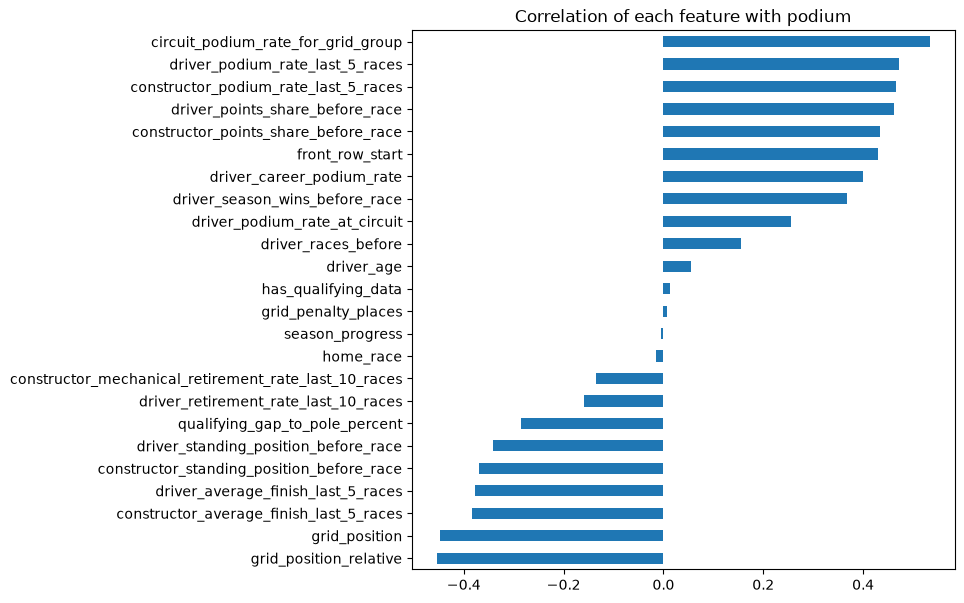

In [57]:
df[features].corrwith(df['podium']).sort_values().plot(kind='barh', figsize=(7, 7), title='Correlation of each feature with podium')
plt.show()

No feature is close to 1 or -1. The strongest are the grid features and the recent form of the driver and the team, as expected. `circuit_podium_rate_for_grid_group` is at the top because it is built from grid.

## 9. Save

The split is by season: train up to 2019, validation 2020-2021, test from 2022. `year` is only used for the split, it is not a feature.

In [58]:
df['split'] = 'train'
df.loc[df['year'] >= 2020, 'split'] = 'val'
df.loc[df['year'] >= 2022, 'split'] = 'test'

df.groupby('split')['podium'].agg(['count', 'mean'])

,count,mean
split,,
test,1352,0.150888
train,22444,0.135359
val,775,0.150968


Missing values that are left. We do **not** fill them here: any fill value (median, mean, mode) must be learned from the training rows only, so it belongs in the modeling notebook.

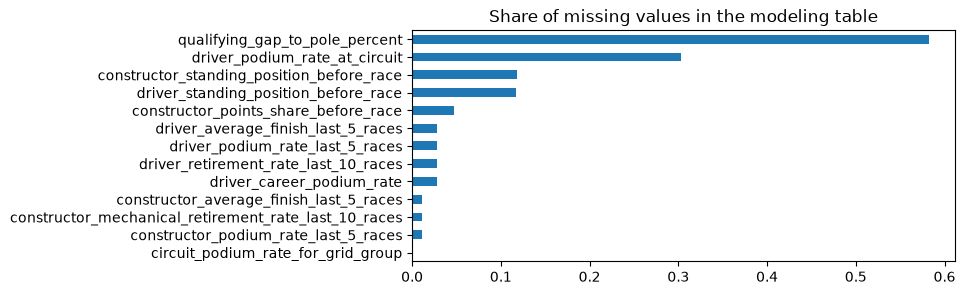

In [59]:
keys = ['raceId', 'driverId', 'constructorId', 'circuitId', 'year', 'round', 'date', 'split']
model_table = df[keys + ['podium'] + features]

missing = model_table.isna().mean()
missing[missing > 0].sort_values().plot(kind='barh', figsize=(7, 3), title='Share of missing values in the modeling table')
plt.show()

Why they are missing:

- `qualifying_gap_to_pole_percent`: no qualifying lap times for most races before 2003.
- `drv_...` form columns: the driver's first race (or first race at this circuit).
- `con_...` form columns: the team's first race.
- `driver_standing_position_before_race`, `constructor_standing_position_before_race`: round 1, or no points yet.
- `constructor_points_share_before_race`: before the constructors' championship started in 1958.
- `circuit_podium_rate_for_grid_group`: the very first race, which has no earlier race at all.

In [60]:
os.makedirs(OUT_DIR, exist_ok=True)
model_table.to_csv(OUT_DIR + '/modeling_table.csv', index=False)

model_table.shape

(24571, 33)